# 01 · Data Acquisition, Exploratory Data Analysis and Preprocessing
**Project:** Deep Learning-Based Skin Cancer Detection and Classification Using Dermoscopic Image Analysis

> An innovative artificial intelligence framework is introduced for automated skin cancer detection using deep learning architectures and computer vision techniques. Raw dermoscopic images undergo image enhancement, resizing, and pixel normalization. Convolutional neural networks extract key diagnostic features such as lesion shape, color variations, and border irregularities. Transfer learning models classify lesions into benign or malignant categories with confidence scores. Explainable AI methods like Grad-CAM heat maps highlight the regions influencing the model's decisions. The system generates clinical evaluation metrics and exports reports as PDF or CSV.

This notebook:
1. downloads the **HAM10000** dataset with the Kaggle API,
2. explores it (class distribution, sample images, age / sex / localisation),
3. demonstrates the preprocessing pipeline (hair removal, CLAHE, resize, normalisation) with before/after visuals,
4. creates the **stratified, lesion-grouped train / validation / test split** and saves it to `data/splits/`,
5. caches the preprocessed images used by the model notebooks (02-04).

## 0. Environment setup
This first cell detects whether the notebook runs on **Google Colab**. On Colab it installs the
required packages and uses `/content/skin-cancer-detection` as the project folder (select
*Runtime → Change runtime type → GPU*). Locally it uses the project root (the parent of `notebooks/`).
All paths are built with `pathlib`, so the notebook runs unchanged on macOS, Linux and Windows.

In [1]:
import sys, subprocess, os, json, time, random, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle", "opencv-python-headless",
                    "seaborn", "scikit-learn", "pandas", "matplotlib"], check=True)
    ROOT = Path("/content/skin-cancer-detection")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                # original HAM10000 download
PROCESSED_DIR = DATA_DIR / "processed"    # cached preprocessed 224x224 images
SPLITS_DIR = DATA_DIR / "splits"          # train/val/test CSVs
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
for d in (RAW_DIR, PROCESSED_DIR, SPLITS_DIR, MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=UserWarning)
print("Running on Colab:", IN_COLAB)
print("Project root   :", ROOT)

Running on Colab: False
Project root   : /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection


## 1. Download HAM10000 (Kaggle API)
The dataset `kmader/skin-cancer-mnist-ham10000` is downloaded with the official `kaggle` package.
Both credential formats are supported: the **new API token** (`~/.kaggle/access_token` or the
`KAGGLE_API_TOKEN` environment variable) and the legacy `~/.kaggle/kaggle.json`. On Colab you are
asked to paste a token if none is configured. If the data is already present, the download is skipped.

In [2]:
import getpass

KAGGLE_DATASET = "kmader/skin-cancer-mnist-ham10000"

def dataset_present():
    has_csv = any(RAW_DIR.rglob("HAM10000_metadata.csv"))
    return has_csv and sum(1 for _ in RAW_DIR.rglob("ISIC_*.jpg")) >= 10000

def ensure_dataset():
    if dataset_present():
        print(f"HAM10000 already available in {RAW_DIR}")
        return
    kdir = Path.home() / ".kaggle"
    has_creds = (os.environ.get("KAGGLE_API_TOKEN") or (kdir / "access_token").exists()
                 or (kdir / "kaggle.json").exists())
    if not has_creds and IN_COLAB:
        kdir.mkdir(exist_ok=True)
        (kdir / "access_token").write_text(getpass.getpass("Paste your Kaggle API token: ").strip())
        os.chmod(kdir / "access_token", 0o600)
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    print("Downloading HAM10000 (~2.7 GB) ...")
    api.dataset_download_files(KAGGLE_DATASET, path=str(RAW_DIR), unzip=True, quiet=False)
    print("Download complete:", dataset_present())

ensure_dataset()

HAM10000 already available in /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/raw


## 2. Configuration
Class names, the benign/malignant mapping, preprocessing parameters and the compute device
(**CUDA → Apple MPS → CPU**).

In [3]:
import numpy as np
import pandas as pd
import torch

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_FULL_NAMES = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma", "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions", "df": "Dermatofibroma", "mel": "Melanoma",
    "nv": "Melanocytic nevi", "vasc": "Vascular lesions"}
MALIGNANT_CLASSES = ["mel", "bcc", "akiec"]
BENIGN_CLASSES = ["nv", "bkl", "df", "vasc"]
BINARY_MAP = {c: ("Malignant" if c in MALIGNANT_CLASSES else "Benign") for c in CLASS_NAMES}
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
MALIGNANT_IDX = [CLASS_TO_IDX[c] for c in MALIGNANT_CLASSES]

IMG_SIZE = 224
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
HAIR_KERNEL_SIZE, HAIR_THRESHOLD, HAIR_MIN_LENGTH, INPAINT_RADIUS = 17, 12, 40, 3
CLAHE_CLIP_LIMIT, CLAHE_TILE_GRID = 2.0, (8, 8)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
SEED = 42

def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

DEVICE = get_device()
set_seed()
print("PyTorch", torch.__version__, "| device:", DEVICE)

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

PyTorch 2.14.1 | device: mps


## Preprocessing functions
The same preprocessing is used for training, evaluation and inference:

1. **Hair removal.** A morphological **black-hat** transform (closing minus image) highlights thin,
   dark structures such as hairs. After thresholding, only **long and thin** connected components are
   kept (so skin texture and the lesion's own pigment network are *not* erased), and the masked
   pixels are filled by **Telea inpainting**.
2. **CLAHE.** Contrast Limited Adaptive Histogram Equalisation on the *L* (lightness) channel of the
   LAB colour space enhances local contrast (borders, pigment network) without shifting lesion colours.
3. **Resize** to 224 × 224 pixels, the input size of the ImageNet backbones.
4. **Normalise** pixel values to [0, 1], then standardise with the ImageNet channel mean and std.

In [4]:
import cv2

def load_image_rgb(path):
    data = np.fromfile(str(path), dtype=np.uint8)          # works with non-ASCII Windows paths
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Could not read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def hair_mask(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (HAIR_KERNEL_SIZE, HAIR_KERNEL_SIZE))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask = cv2.threshold(blackhat, HAIR_THRESHOLD, 255, cv2.THRESH_BINARY)
    # keep only long, thin components (hairs); drops skin texture and the lesion's pigment network
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    w, h, area = stats[:, cv2.CC_STAT_WIDTH], stats[:, cv2.CC_STAT_HEIGHT], stats[:, cv2.CC_STAT_AREA]
    keep = (np.maximum(w, h) >= HAIR_MIN_LENGTH) & (area / np.maximum(w * h, 1) < 0.4)
    keep[0] = False
    mask = np.where(keep[labels], 255, 0).astype(np.uint8)
    return blackhat, cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=1)

def remove_hair(img_rgb):
    _, mask = hair_mask(img_rgb)
    return cv2.inpaint(img_rgb, mask, INPAINT_RADIUS, cv2.INPAINT_TELEA)

def apply_clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID)
    return cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2RGB)

def preprocess_image(img_rgb, size=IMG_SIZE):
    """hair removal -> CLAHE -> resize. Returns RGB uint8 (size x size)."""
    h, w = img_rgb.shape[:2]
    scale = 600.0 / max(h, w)                                # fixed working resolution
    if abs(scale - 1.0) > 0.05:
        img_rgb = cv2.resize(img_rgb, (int(round(w * scale)), int(round(h * scale))), interpolation=cv2.INTER_AREA)
    img = apply_clahe(remove_hair(img_rgb))
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def normalize(img_rgb):
    img = img_rgb.astype(np.float32) / 255.0
    return (img - np.array(IMAGENET_MEAN, np.float32)) / np.array(IMAGENET_STD, np.float32)

def save_image_rgb(img_rgb, path):
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
    buf.tofile(str(path))

## 3. Load the metadata

In [5]:
from sklearn.model_selection import train_test_split

def load_metadata():
    csv = sorted(RAW_DIR.rglob("HAM10000_metadata.csv"))[0]
    df = pd.read_csv(csv)
    paths = {}
    for p in RAW_DIR.rglob("ISIC_*.jpg"):
        paths.setdefault(p.stem, p)
    df["path"] = df["image_id"].map(paths)
    df = df.dropna(subset=["path"]).reset_index(drop=True)
    df["label"] = df["dx"].map(CLASS_TO_IDX)
    df["binary"] = df["dx"].map(BINARY_MAP)
    return df

def _resolve(df):
    df = df.copy()
    df["path"] = df["path"].map(lambda rel: str(RAW_DIR / Path(rel)))
    return df

def make_splits(force=False):
    files = {s: SPLITS_DIR / f"{s}.csv" for s in ("train", "val", "test")}
    if not force and all(f.exists() for f in files.values()):
        return {s: _resolve(pd.read_csv(f)) for s, f in files.items()}
    df = load_metadata()
    lesions = df.groupby("lesion_id")["dx"].first().reset_index()
    train_l, rest_l = train_test_split(lesions, test_size=VAL_FRAC + TEST_FRAC,
                                       stratify=lesions["dx"], random_state=SEED)
    val_l, test_l = train_test_split(rest_l, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                     stratify=rest_l["dx"], random_state=SEED)
    splits = {}
    for name, lesion_df in (("train", train_l), ("val", val_l), ("test", test_l)):
        part = df[df["lesion_id"].isin(set(lesion_df["lesion_id"]))].copy()
        part["path"] = part["path"].map(lambda p: Path(p).relative_to(RAW_DIR).as_posix())
        part.to_csv(files[name], index=False)
        splits[name] = _resolve(part)
    return splits

df = load_metadata()
print(f"Images: {len(df)} | unique lesions: {df.lesion_id.nunique()} | columns: {list(df.columns)}")
df.head()

Images: 10015 | unique lesions: 7470 | columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'path', 'label', 'binary']


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,label,binary
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/Users/udaymallikarjun/Documents/sanya/skincan...,2,Benign
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/Users/udaymallikarjun/Documents/sanya/skincan...,2,Benign
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/Users/udaymallikarjun/Documents/sanya/skincan...,2,Benign
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/Users/udaymallikarjun/Documents/sanya/skincan...,2,Benign
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/Users/udaymallikarjun/Documents/sanya/skincan...,2,Benign


In [6]:
imgs_per_lesion = df.groupby("lesion_id").size()
print("Images per lesion:")
print(imgs_per_lesion.value_counts().sort_index().rename("lesions").to_string())
print(f"\n{(imgs_per_lesion > 1).sum()} lesions have more than one image -> splitting by lesion_id is required.")
print("\nDiagnosis confirmation method (dx_type):")
print(df.dx_type.value_counts().to_string())

Images per lesion:
1    5514
2    1423
3     490
4      34
5       5
6       4

1956 lesions have more than one image -> splitting by lesion_id is required.

Diagnosis confirmation method (dx_type):
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69


## 4. Exploratory data analysis
### 4.1 Class distribution
HAM10000 is **heavily imbalanced**: melanocytic nevi (`nv`) dominate, while dermatofibroma (`df`) and
vascular lesions (`vasc`) are rare. This motivates the class-weighted loss and macro-averaged metrics
used in the model notebooks.

,diagnosis,group,images,percent
akiec,Actinic keratoses / intraepithelial carcinoma,Malignant,327,3.27
bcc,Basal cell carcinoma,Malignant,514,5.13
bkl,Benign keratosis-like lesions,Benign,1099,10.97
df,Dermatofibroma,Benign,115,1.15
mel,Melanoma,Malignant,1113,11.11
nv,Melanocytic nevi,Benign,6705,66.95
vasc,Vascular lesions,Benign,142,1.42


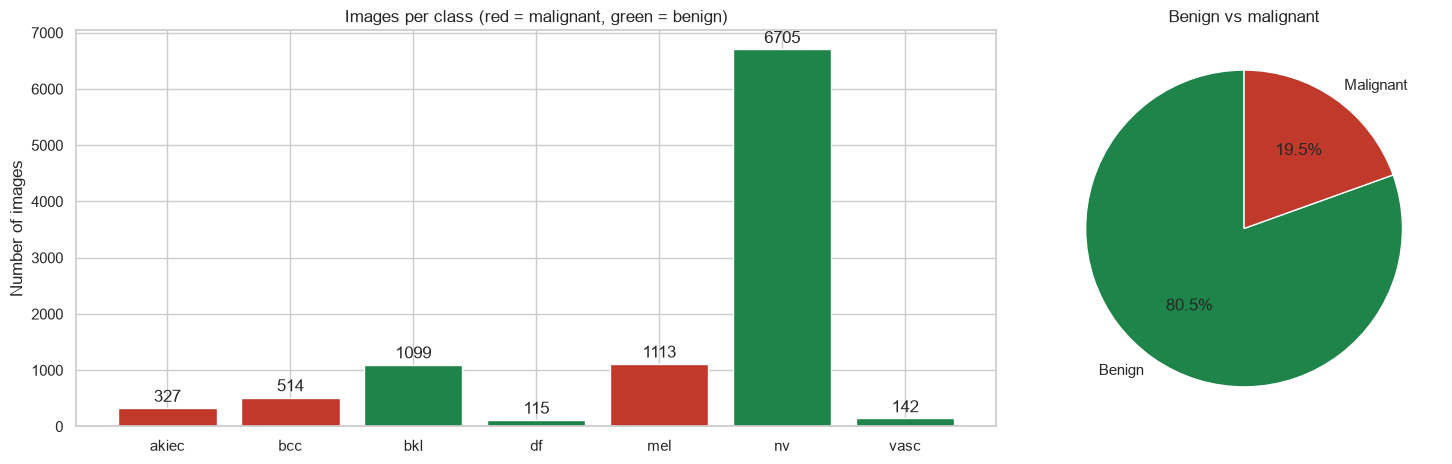

In [7]:
counts = df.dx.value_counts().reindex(CLASS_NAMES)
summary = pd.DataFrame({"diagnosis": [CLASS_FULL_NAMES[c] for c in CLASS_NAMES],
                        "group": [BINARY_MAP[c] for c in CLASS_NAMES],
                        "images": counts.values,
                        "percent": (100 * counts / counts.sum()).round(2).values}, index=CLASS_NAMES)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 1]})
colors = ["#c0392b" if BINARY_MAP[c] == "Malignant" else "#1e8449" for c in CLASS_NAMES]
bars = axes[0].bar(CLASS_NAMES, counts.values, color=colors)
axes[0].bar_label(bars, padding=2)
axes[0].set_title("Images per class (red = malignant, green = benign)")
axes[0].set_ylabel("Number of images")
bin_counts = df.binary.value_counts()
axes[1].pie(bin_counts.values, labels=bin_counts.index, autopct="%1.1f%%",
            colors=["#1e8449" if i == "Benign" else "#c0392b" for i in bin_counts.index], startangle=90)
axes[1].set_title("Benign vs malignant")
plt.tight_layout(); plt.savefig(EDA_DIR / "class_distribution.png", dpi=150); plt.show()

### 4.2 Sample images per class
Five random dermoscopic images for each of the seven diagnostic categories.

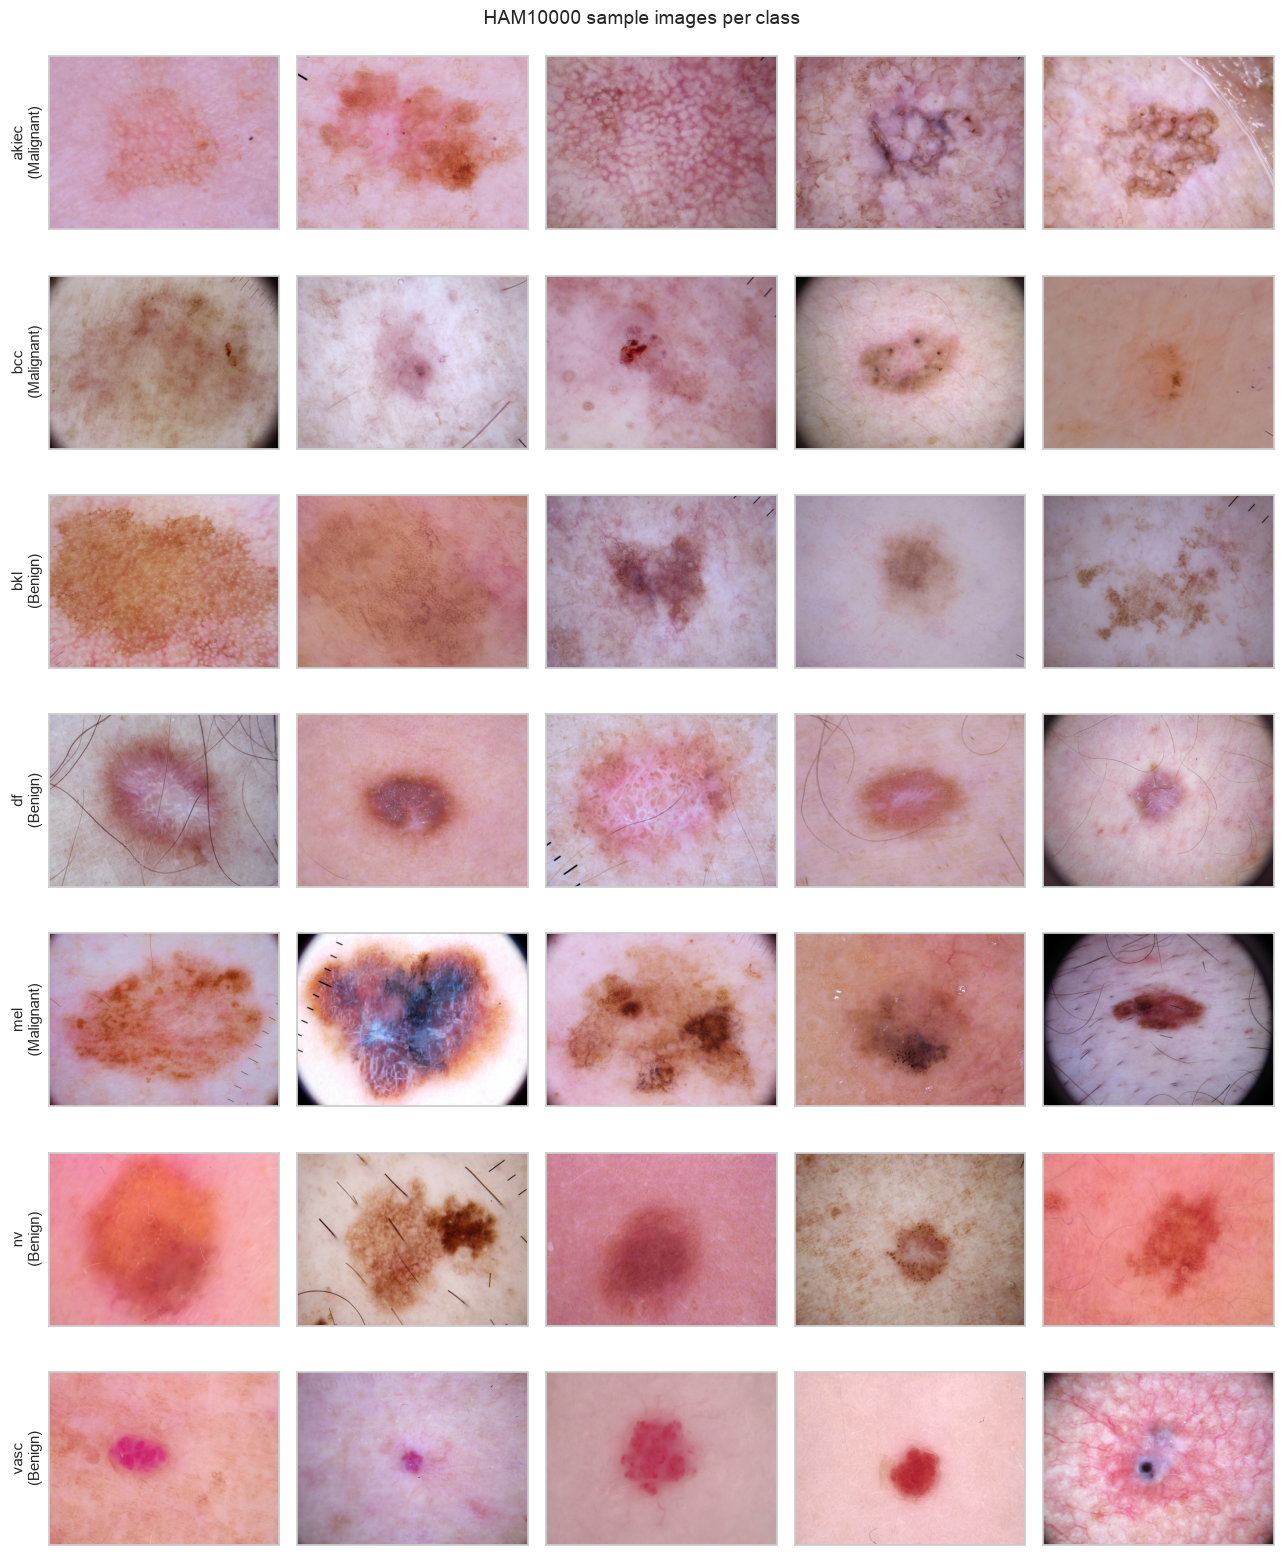

In [8]:
n_per = 5
fig, axes = plt.subplots(len(CLASS_NAMES), n_per, figsize=(2.6 * n_per, 2.3 * len(CLASS_NAMES)))
for r, c in enumerate(CLASS_NAMES):
    rows = df[df.dx == c].sample(n_per, random_state=SEED)
    for j, row in enumerate(rows.itertuples()):
        ax = axes[r, j]
        ax.imshow(load_image_rgb(row.path)); ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"{c}\n({BINARY_MAP[c]})", fontsize=11)
plt.suptitle("HAM10000 sample images per class", fontsize=14)
plt.tight_layout(); plt.savefig(EDA_DIR / "samples_per_class.png", dpi=120); plt.show()

### 4.3 Patient age, sex and lesion localisation

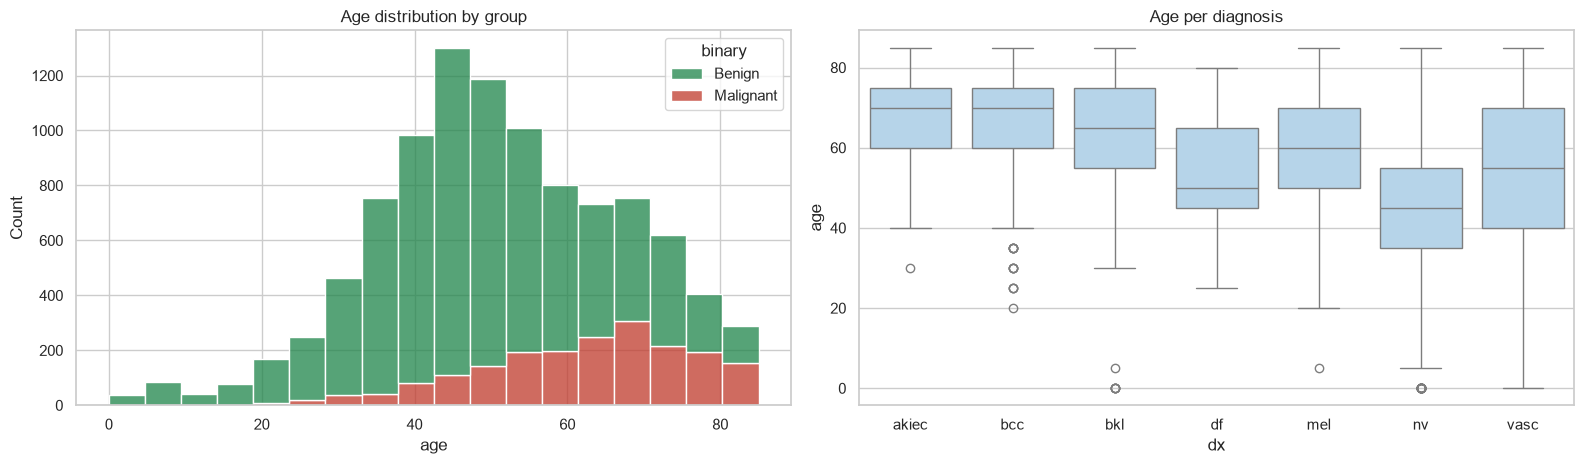

Missing age values: 57


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.histplot(df, x="age", hue="binary", bins=18, multiple="stack", ax=axes[0],
             palette={"Benign": "#1e8449", "Malignant": "#c0392b"})
axes[0].set_title("Age distribution by group")
sns.boxplot(df, x="dx", y="age", order=CLASS_NAMES, ax=axes[1], color="#aed6f1")
axes[1].set_title("Age per diagnosis")
plt.tight_layout(); plt.savefig(EDA_DIR / "age.png", dpi=150); plt.show()
print("Missing age values:", df.age.isna().sum())

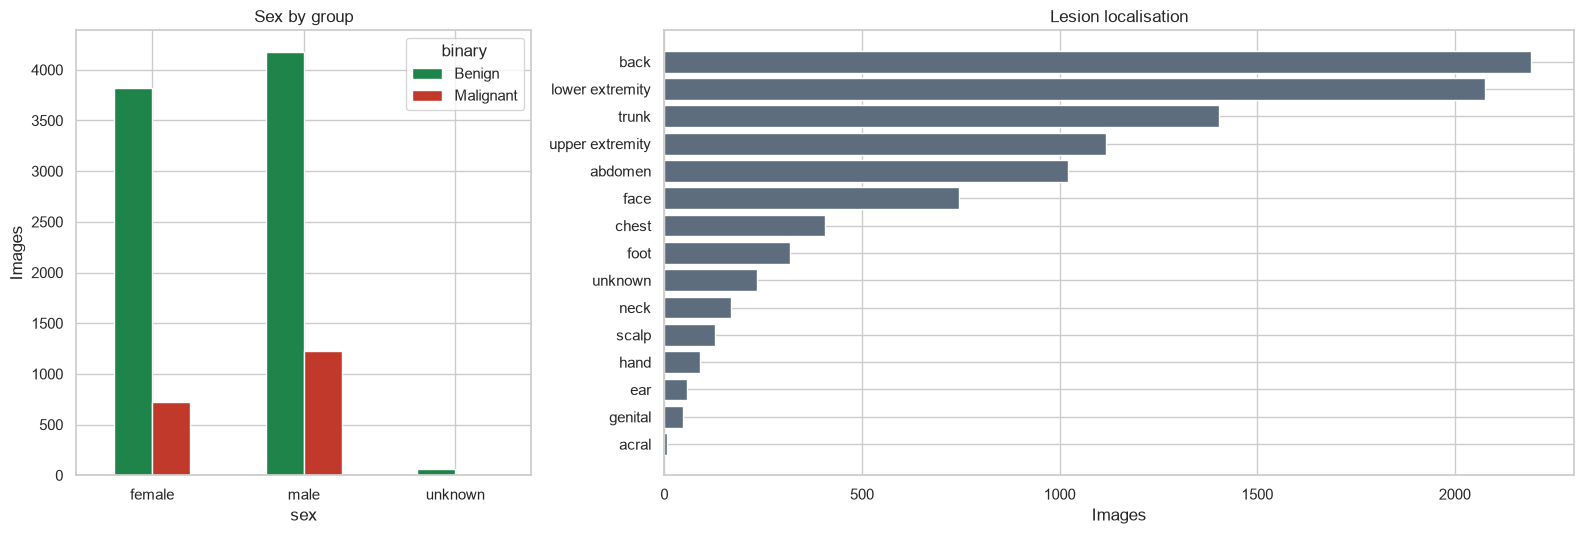

dx,akiec,bcc,bkl,df,mel,nv,vasc
localization,,,,,,,
back,29,186,202,2,324,1427,22
lower extremity,65,58,174,82,192,1479,27
trunk,1,11,73,0,47,1241,31
upper extremity,62,49,104,24,213,655,11
abdomen,5,18,42,4,66,860,27
face,113,101,319,0,104,100,8
chest,12,47,74,0,68,200,6
foot,0,4,1,2,28,284,0
unknown,0,5,23,0,10,196,0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 2]})
sex_ct = pd.crosstab(df.sex, df.binary)
sex_ct.plot.bar(ax=axes[0], color=["#1e8449", "#c0392b"], rot=0)
axes[0].set_title("Sex by group"); axes[0].set_ylabel("Images")
loc = df.localization.value_counts()
axes[1].barh(loc.index[::-1], loc.values[::-1], color="#5d6d7e")
axes[1].set_title("Lesion localisation"); axes[1].set_xlabel("Images")
plt.tight_layout(); plt.savefig(EDA_DIR / "sex_localization.png", dpi=150); plt.show()
display(pd.crosstab(df.localization, df.dx).loc[loc.index])

## 5. Preprocessing pipeline: before / after
### 5.1 Hair removal step by step
The black-hat response is strong only on thin dark structures, so the threshold isolates hairs while
leaving the (larger) lesion untouched. The masked pixels are then reconstructed by inpainting.

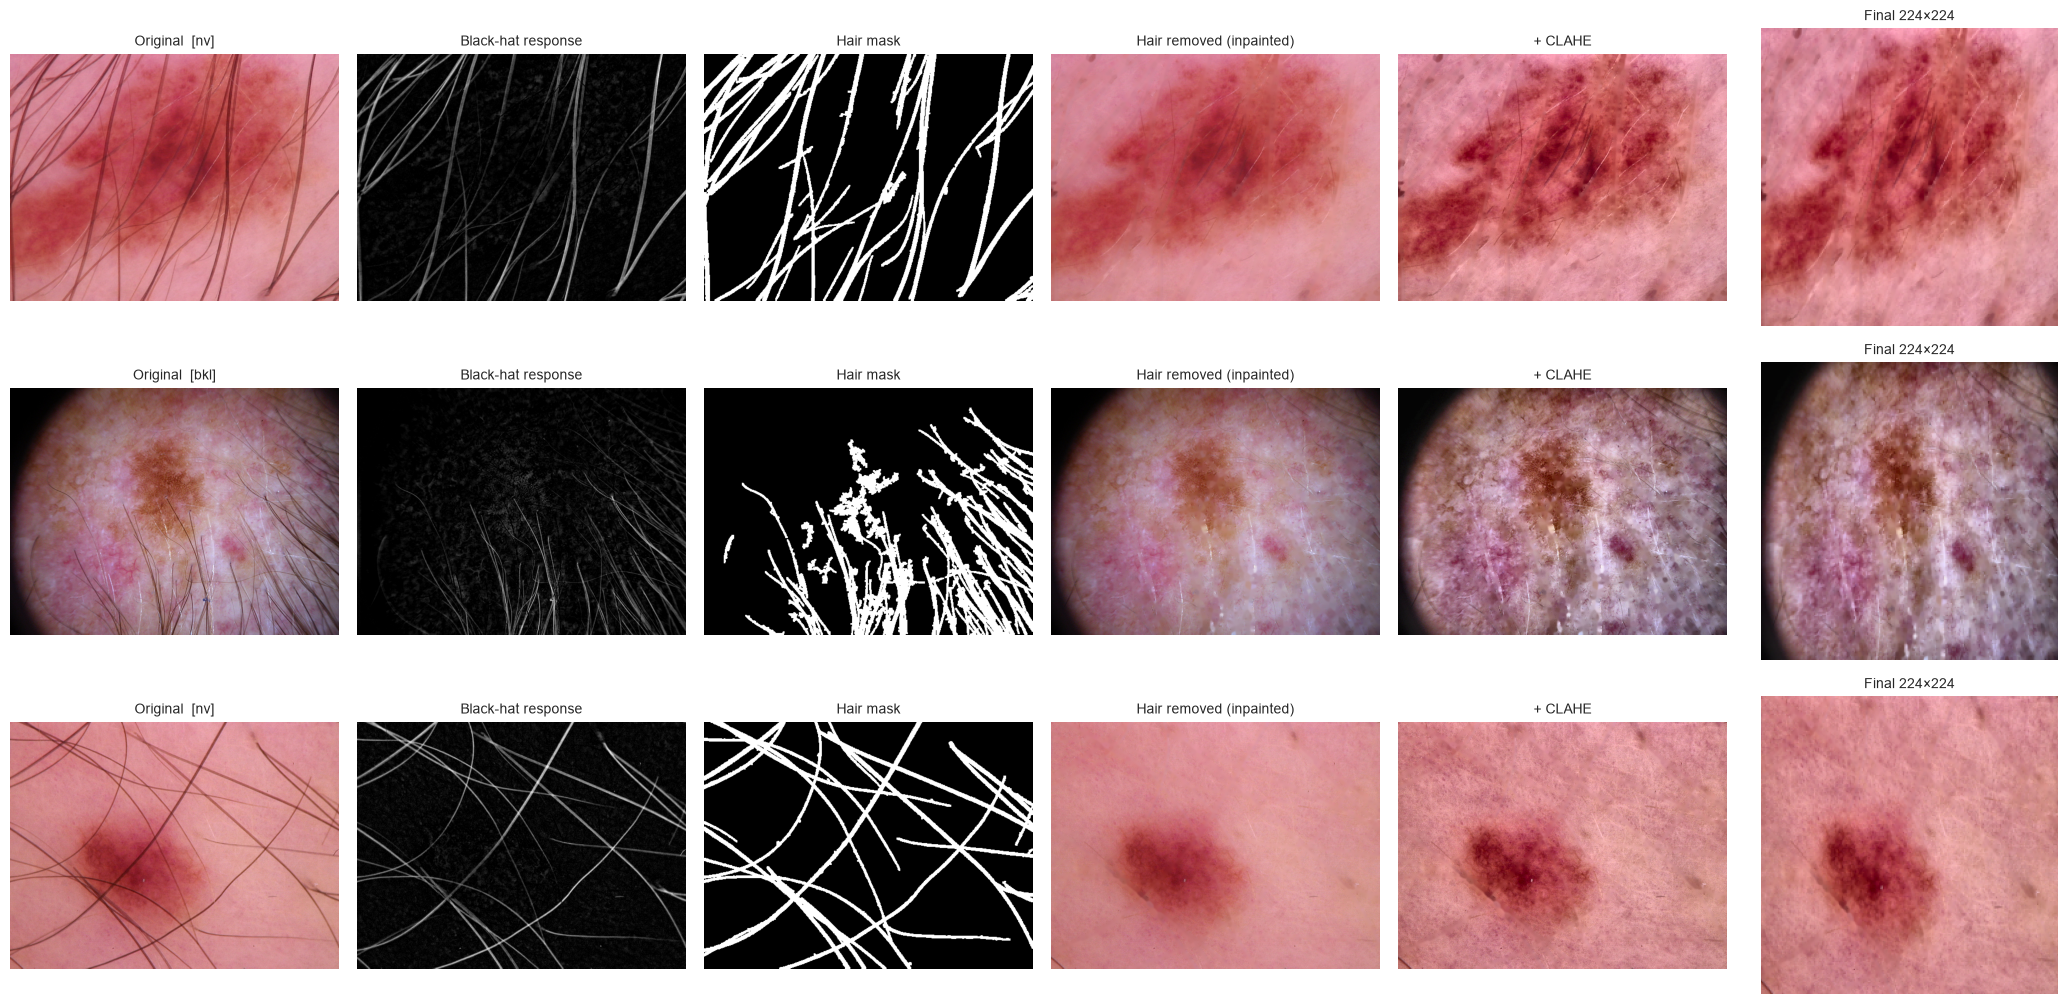

In [11]:
# choose the images with the most hair (largest mask area) among a random sample
cand = df.sample(150, random_state=1)
scores = [(hair_mask(load_image_rgb(p))[1] > 0).mean() for p in cand.path]
hairy = cand.iloc[np.argsort(scores)[::-1][:3]]

titles = ["Original", "Black-hat response", "Hair mask", "Hair removed (inpainted)", "+ CLAHE", "Final 224×224"]
fig, axes = plt.subplots(len(hairy), 6, figsize=(21, 3.4 * len(hairy)))
for r, row in enumerate(hairy.itertuples()):
    img = load_image_rgb(row.path)
    bh, mask = hair_mask(img)
    no_hair = remove_hair(img)
    steps = [img, bh, mask, no_hair, apply_clahe(no_hair), preprocess_image(img)]
    for ax, im, t in zip(axes[r], steps, titles):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.axis("off")
        ax.set_title(f"{t}" + (f"  [{row.dx}]" if t == "Original" else ""), fontsize=10)
plt.tight_layout(); plt.savefig(EDA_DIR / "preprocessing_steps.png", dpi=120); plt.show()

### 5.2 Before / after on one image per class

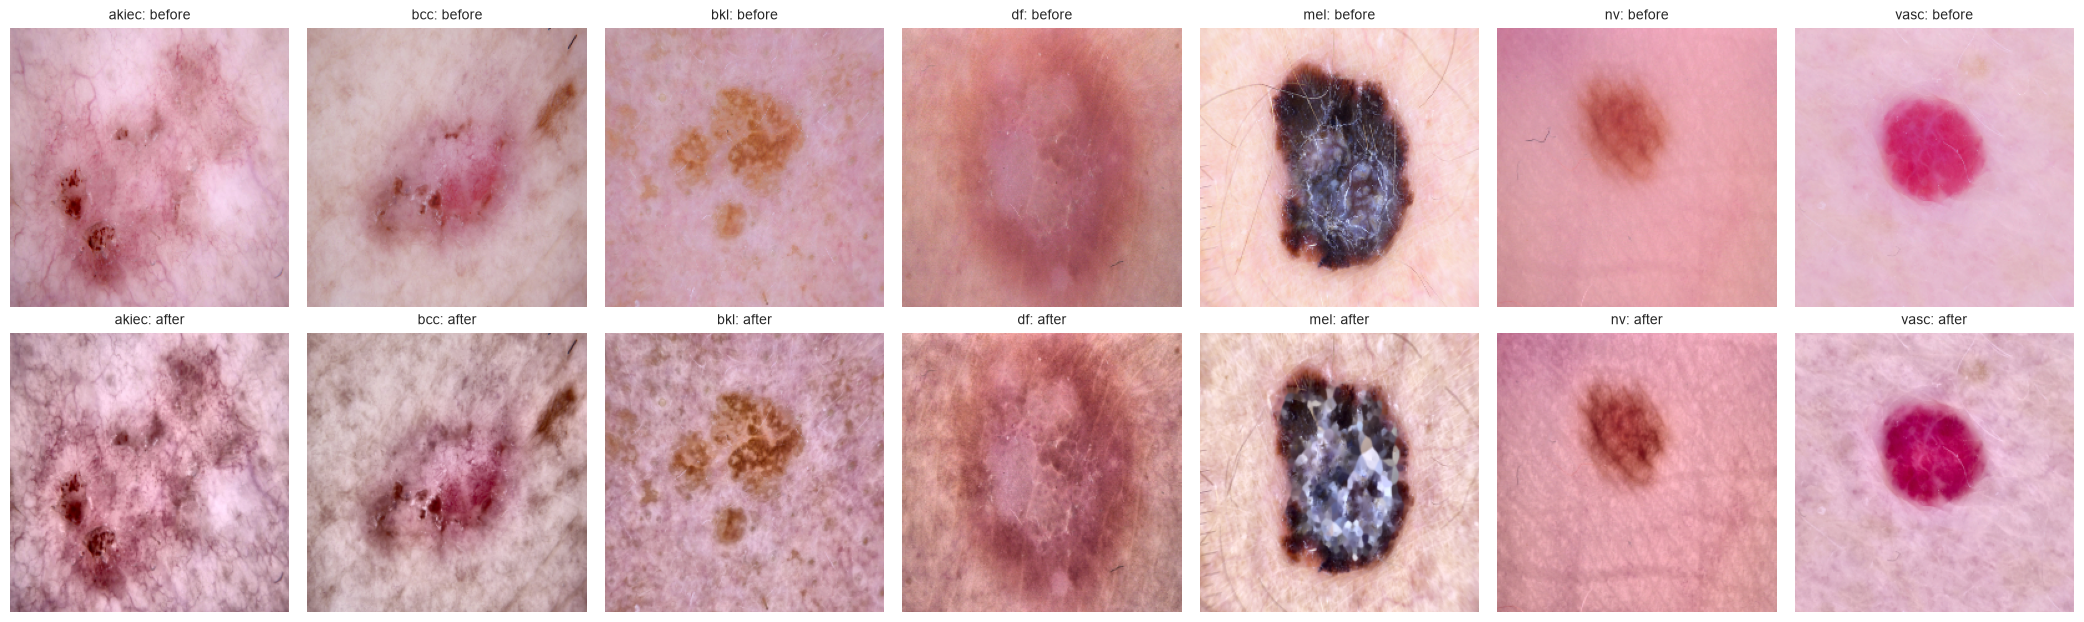

In [12]:
fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(3 * len(CLASS_NAMES), 6.4))
for j, c in enumerate(CLASS_NAMES):
    row = df[df.dx == c].sample(1, random_state=7).iloc[0]
    img = load_image_rgb(row.path)
    axes[0, j].imshow(cv2.resize(img, (IMG_SIZE, IMG_SIZE))); axes[0, j].set_title(f"{c}: before", fontsize=10)
    axes[1, j].imshow(preprocess_image(img)); axes[1, j].set_title(f"{c}: after", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.savefig(EDA_DIR / "before_after.png", dpi=120); plt.show()

### 5.3 Normalisation
After resizing, pixels are scaled to [0, 1] and standardised per channel with the ImageNet mean and
standard deviation, because the pre-trained backbones expect inputs with these statistics.

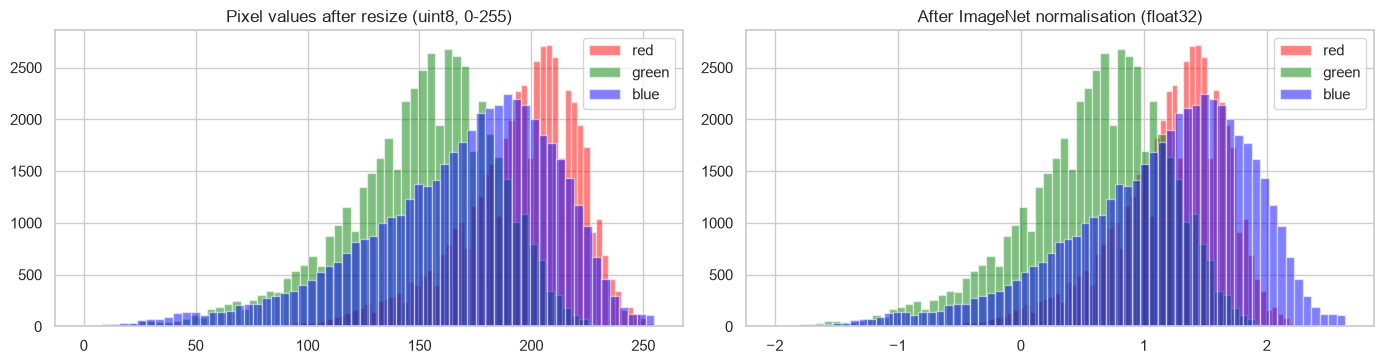

normalised mean per channel: [1.22  0.59  1.139] | std: [0.46  0.603 0.745]


In [13]:
img = preprocess_image(load_image_rgb(df.iloc[0].path))
norm = normalize(img)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ch, col in enumerate(["red", "green", "blue"]):
    axes[0].hist(img[..., ch].ravel(), bins=64, color=col, alpha=0.5, label=col)
    axes[1].hist(norm[..., ch].ravel(), bins=64, color=col, alpha=0.5, label=col)
axes[0].set_title("Pixel values after resize (uint8, 0-255)")
axes[1].set_title("After ImageNet normalisation (float32)")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
print("normalised mean per channel:", norm.reshape(-1, 3).mean(0).round(3), "| std:", norm.reshape(-1, 3).std(0).round(3))

## 6. Leakage-free train / validation / test split
HAM10000 contains several images of the same lesion. If those images ended up in both the training
and the test set, the model could memorise the lesion and the test score would be inflated. We
therefore split **unique `lesion_id`s** (70 / 15 / 15, stratified by diagnosis, seed 42), and every
image follows its lesion. Paths in the CSVs are stored relative to `data/raw/` so the files are
portable between machines and operating systems.

In [14]:
splits = make_splits(force=True)
for name, part in splits.items():
    print(f"{name:5s}: {len(part):5d} images | {part.lesion_id.nunique():5d} lesions | saved to {SPLITS_DIR / (name + '.csv')}")

# leakage check: no lesion may appear in two splits
tr, va, te = (set(splits[s].lesion_id) for s in ("train", "val", "test"))
assert not (tr & va) and not (tr & te) and not (va & te), "lesion leakage between splits!"
print("\nLeakage check passed: every lesion_id belongs to exactly one split.")

dist = pd.DataFrame({s: splits[s].dx.value_counts().reindex(CLASS_NAMES) for s in splits})
dist_pct = (100 * dist / dist.sum()).round(1).add_suffix(" %")
display(pd.concat([dist, dist_pct], axis=1))

train:  6981 images |  5229 lesions | saved to /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/splits/train.csv
val  :  1532 images |  1120 lesions | saved to /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/splits/val.csv
test :  1502 images |  1121 lesions | saved to /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/splits/test.csv

Leakage check passed: every lesion_id belongs to exactly one split.


,train,val,test,train %,val %,test %
dx,,,,,,
akiec,222,53,52,3.2,3.5,3.5
bcc,361,82,71,5.2,5.4,4.7
bkl,772,160,167,11.1,10.4,11.1
df,71,24,20,1.0,1.6,1.3
mel,773,173,167,11.1,11.3,11.1
nv,4683,1018,1004,67.1,66.4,66.8
vasc,99,22,21,1.4,1.4,1.4


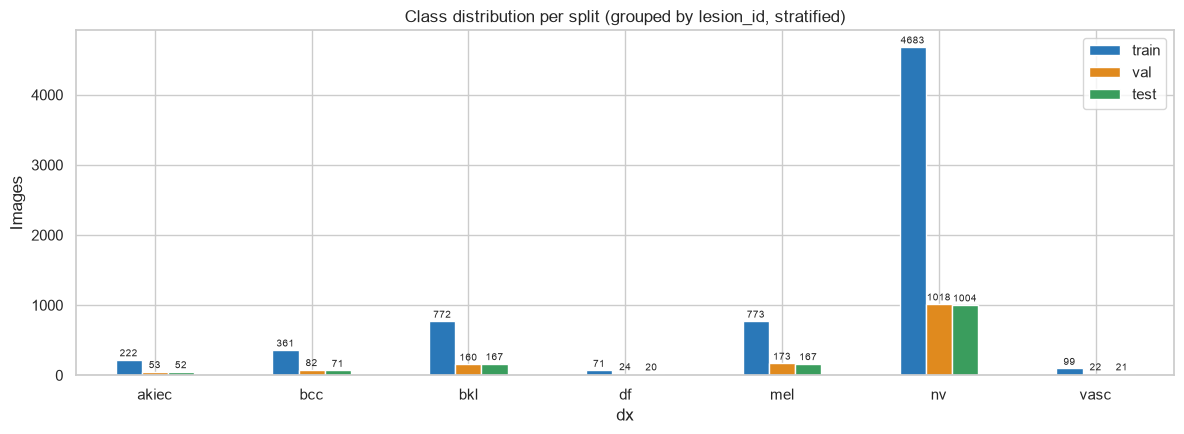

In [15]:
ax = dist.plot.bar(figsize=(12, 4.5), color=["#2a78b8", "#e08a1e", "#3a9d5d"], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=7, padding=1)
ax.set_title("Class distribution per split (grouped by lesion_id, stratified)"); ax.set_ylabel("Images")
plt.tight_layout(); plt.savefig(EDA_DIR / "split_distribution.png", dpi=150); plt.show()

## 7. Cache the preprocessed images
Hair removal and inpainting are the most expensive steps, so every image is preprocessed **once**
and stored in `data/processed/`. The model notebooks read from this cache (and rebuild it
automatically if it is missing).

In [16]:
def build_cache(df, verbose=True):
    """Preprocess every image once and store it in data/processed/ (skips existing files)."""
    todo = [r for r in df.itertuples(index=False) if not (PROCESSED_DIR / f"{r.image_id}.jpg").exists()]
    t0 = time.time()
    for i, r in enumerate(todo, 1):
        save_image_rgb(preprocess_image(load_image_rgb(r.path)), PROCESSED_DIR / f"{r.image_id}.jpg")
        if verbose and (i % 1000 == 0 or i == len(todo)):
            print(f"  preprocessed {i}/{len(todo)} images ({time.time() - t0:.0f}s)")
    if verbose:
        print(f"Cache ready: {sum(1 for _ in PROCESSED_DIR.glob('*.jpg'))} preprocessed images in {PROCESSED_DIR}")

build_cache(pd.concat(splits.values()))

Cache ready: 10015 preprocessed images in /Users/udaymallikarjun/Documents/sanya/skincancer/skin-cancer-detection/data/processed


## Summary
* 10,015 dermoscopic images, 7 classes, strong class imbalance (nv ≈ 67%).
* Preprocessing removes hair and enhances contrast before resizing and normalisation.
* Train / validation / test CSVs (70 / 15 / 15, lesion-grouped) are saved in `data/splits/`.
* Next: train the models in notebooks **02** (EfficientNet-B0), **03** (ResNet50) and **04** (DenseNet121).